# (PROJECT) TO CREATE A SCRIPT WHICH AUTOMATICALLY TAKES DATA FROM A CRYPTO API 

In [2]:
import json
import ssl
import urllib.parse
import urllib.request

import certifi

params = urllib.parse.urlencode(
    {
        "start": "1",
        "limit": "15",
        "convert": "USD",
    }
)

request = urllib.request.Request(
    f"https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest?{params}",
    headers={
        "Accept": "application/json",
        "X-CMC_PRO_API_KEY": "6befc53e076a4959b82242d7eb73fd04",
    },
)

context = ssl.create_default_context(cafile=certifi.where())

with urllib.request.urlopen(request, context=context) as response:
    data = json.load(response)

print(data)

{'data': [{'id': 1, 'name': 'Bitcoin', 'symbol': 'BTC', 'slug': 'bitcoin', 'infinite_supply': False, 'circulating_supply': 20091365, 'total_supply': 20091365, 'max_supply': 21000000, 'date_added': '2010-07-13T00:00:00.000Z', 'num_market_pairs': 12753, 'cmc_rank': 1, 'last_updated': '2026-10-01T14:14:00.000Z', 'tvl_ratio': None, 'platform': None, 'self_reported_circulating_supply': None, 'self_reported_market_cap': None, 'minted_market_cap': 1683006622009.22, 'quote': {'USD': {'price': 83767.65948999564, 'volume_24h': 31402888710.476456, 'cex_volume_24h': 31370697146.941067, 'dex_volume_24h': 32191563.53539156, 'volume_change_24h': -8.1138, 'percent_change_1h': 0.33148209, 'percent_change_24h': -0.66213584, 'percent_change_7d': -0.53235845, 'percent_change_30d': 7.06312949, 'percent_change_60d': 32.91183458, 'percent_change_90d': 35.8225571, 'market_cap': 1683006622009.2163, 'market_cap_dominance': 58.6487, 'fully_diluted_market_cap': 1759120849289.91, 'tvl': None, 'last_updated': '2026

In [3]:
type(data)

dict

In [4]:
import pandas as pd

pd.set_option('display.max_columns',None)

pd.set_option('display.max_rows',None)

In [5]:
df = pd.json_normalize(data['data'])

df['timestamp'] = pd.to_datetime('now')
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.009136e+07,2.009136e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12753,1,2026-10-01T14:14:00.000Z,None,NaN,NaN,NaN,1.683007e+12,"[mineable, pow, sha-256, store-of-value, state...",83767.659490,3.140289e+10,3.137070e+10,3.219156e+07,-8.1138,0.331482,-0.662136,-0.532358,7.063129,32.911835,35.822557,1.683007e+12,58.6487,1.759121e+12,None,2026-10-01T14:14:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:37.505566
1,1027,Ethereum,ETH,ethereum,True,1.220958e+08,1.220958e+08,NaN,2015-08-07T00:00:00.000Z,13860,2,2026-10-01T14:14:00.000Z,None,NaN,NaN,NaN,3.281935e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",2687.999220,1.288539e+10,1.259171e+10,2.936764e+08,-10.4253,0.024716,-0.458920,0.790673,9.703297,45.018066,55.198710,3.281935e+11,11.4367,3.281935e+11,None,2026-10-01T14:14:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:37.505566
2,825,Tether USDt,USDT,tether,True,1.838707e+11,1.893265e+11,NaN,2015-02-25T00:00:00.000Z,202659,3,2026-10-01T14:13:00.000Z,None,NaN,NaN,NaN,1.892507e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.999600,7.502433e+10,7.347646e+10,1.547864e+09,-3.5781,-0.021849,0.017263,-0.013801,-0.003958,0.058648,0.064815,1.837971e+11,6.4049,1.892507e+11,None,2026-10-01T14:13:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-01 19:45:37.505566
3,1839,BNB,BNB,bnb,False,1.331594e+08,1.331594e+08,1.331594e+08,2017-07-25T00:00:00.000Z,3490,4,2026-10-01T14:13:00.000Z,None,NaN,NaN,NaN,1.024688e+11,"[marketplace, centralized-exchange, payments, ...",769.520209,1.282744e+09,1.259279e+09,2.346494e+07,-31.8624,0.238757,0.023584,-1.130569,11.902434,32.183780,36.143199,1.024688e+11,3.5708,1.024688e+11,None,2026-10-01T14:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:37.505566
4,52,XRP,XRP,xrp,False,6.309298e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1886,5,2026-10-01T14:13:00.000Z,None,NaN,NaN,NaN,1.483576e+11,"[medium-of-exchange, enterprise-solutions, xrp...",1.483790,2.880790e+09,2.879267e+09,1.522619e+06,-32.9328,0.296664,-2.127618,-1.123295,7.621561,37.443828,33.666131,9.361670e+10,3.2623,1.483790e+11,None,2026-10-01T14:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:37.505566
5,3408,USDC,USDC,usd-coin,False,7.417733e+10,7.417733e+10,NaN,2018-10-08T00:00:00.000Z,45874,6,2026-10-01T14:13:00.000Z,None,NaN,6.090122e+10,6.089265e+10,7.416690e+10,"[medium-of-exchange, stablecoin, asset-backed-...",0.999859,1.872303e+10,1.639328e+10,2.329753e+09,13.6540,-0.014128,0.009734,-0.003807,-0.009771,0.003882,0.006139,7.416690e+10,2.5845,7.416690e+10,None,2026-10-01T14:13:00.000Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-01 19:45:37.505566
6,5426,Solana,SOL,solana,True,5.880049e+08,6.349952e+08,NaN,2020-04-10T00:00:00.000Z,1181,7,2026-10-01T14:14:00.000Z,None,NaN,5.252369e+08,6.180457e+10,7.471982e+10,"[pos, platform, solana-ecosystem, cms-holdings...",117.669892,3.478978e+09,3.472715e+09,6.263618e+06,-13.5575,0.665406,-2.447935,2.356403,14.970784,61.226407,44.914697,6.919047e+10,2.4111,7.471982e+10,None,2026-10-01T14:14:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:37.505566
7,1958,TRON,TRX,tron,True,9.497668e+10,9.497668e+10,NaN,2017-09-13T00:00:00.000Z,1381,8,2026-10-01T14:14:00.000Z,None,NaN,9.

In [6]:
def api_runner():
    global df
    params = urllib.parse.urlencode(
        {
            "start": "1",
            "limit": "15",
            "convert": "USD",
         }
    )

    request = urllib.request.Request(
        f"https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest?{params}",
        headers={
            "Accept": "application/json",
            "X-CMC_PRO_API_KEY": "6befc53e076a4959b82242d7eb73fd04",
        },
    )

    context = ssl.create_default_context(cafile=certifi.where())

    with urllib.request.urlopen(request, context=context) as response:
        data = json.load(response)

    print(data)

    
    df = pd.json_normalize(data['data'])

    df['timestamp'] = pd.to_datetime('now')
    df 

    if not os.path.isfile(r'C:\Users\DELL\Videos\anacondabin\API.csv'):
        df.to_csv(r'C:\Users\DELL\Videos\anacondabin\API.csv',header='column_names')
    else:
        df.to_csv(r'C:\Users\DELL\Videos\anacondabin\API.csv',mode='a',header=False)
    return df

In [7]:
import os
import pandas as pd
from time import sleep

all_runs = []   # list to collect DataFrames

for i in range(5):
    df = api_runner()   # returns one batch
    print(f"API Runner completed - Run {i+1}")
    all_runs.append(df)  # store each batch
    sleep(60)

# Combine all runs into one DataFrame
final_df = pd.concat(all_runs, ignore_index=True)



{'data': [{'id': 1, 'name': 'Bitcoin', 'symbol': 'BTC', 'slug': 'bitcoin', 'infinite_supply': False, 'circulating_supply': 20091365, 'total_supply': 20091365, 'max_supply': 21000000, 'date_added': '2010-07-13T00:00:00.000Z', 'num_market_pairs': 12753, 'cmc_rank': 1, 'last_updated': '2026-10-01T14:14:00.000Z', 'tvl_ratio': None, 'platform': None, 'self_reported_circulating_supply': None, 'self_reported_market_cap': None, 'minted_market_cap': 1683006622009.22, 'quote': {'USD': {'price': 83767.65948999564, 'volume_24h': 31402888710.476456, 'cex_volume_24h': 31370697146.941067, 'dex_volume_24h': 32191563.53539156, 'volume_change_24h': -8.1138, 'percent_change_1h': 0.33148209, 'percent_change_24h': -0.66213584, 'percent_change_7d': -0.53235845, 'percent_change_30d': 7.06312949, 'percent_change_60d': 32.91183458, 'percent_change_90d': 35.8225571, 'market_cap': 1683006622009.2163, 'market_cap_dominance': 58.6487, 'fully_diluted_market_cap': 1759120849289.91, 'tvl': None, 'last_updated': '2026

In [8]:
final_df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,2.009136e+07,2.009136e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12753,1,2026-10-01T14:14:00.000Z,None,NaN,NaN,NaN,1.683007e+12,"[mineable, pow, sha-256, store-of-value, state...",83767.659490,3.140289e+10,3.137070e+10,3.219156e+07,-8.1138,0.331482,-0.662136,-0.532358,7.063129,32.911835,35.822557,1.683007e+12,58.6487,1.759121e+12,None,2026-10-01T14:14:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:38.984447
1,1027,Ethereum,ETH,ethereum,True,1.220958e+08,1.220958e+08,NaN,2015-08-07T00:00:00.000Z,13860,2,2026-10-01T14:14:00.000Z,None,NaN,NaN,NaN,3.281935e+11,"[pos, smart-contracts, ethereum-ecosystem, coi...",2687.999220,1.288539e+10,1.259171e+10,2.936764e+08,-10.4253,0.024716,-0.458920,0.790673,9.703297,45.018066,55.198710,3.281935e+11,11.4367,3.281935e+11,None,2026-10-01T14:14:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:38.984447
2,825,Tether USDt,USDT,tether,True,1.838707e+11,1.893265e+11,NaN,2015-02-25T00:00:00.000Z,202659,3,2026-10-01T14:13:00.000Z,None,NaN,NaN,NaN,1.892507e+11,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.999600,7.502433e+10,7.347646e+10,1.547864e+09,-3.5781,-0.021849,0.017263,-0.013801,-0.003958,0.058648,0.064815,1.837971e+11,6.4049,1.892507e+11,None,2026-10-01T14:13:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-01 19:45:38.984447
3,1839,BNB,BNB,bnb,False,1.331594e+08,1.331594e+08,1.331594e+08,2017-07-25T00:00:00.000Z,3490,4,2026-10-01T14:13:00.000Z,None,NaN,NaN,NaN,1.024688e+11,"[marketplace, centralized-exchange, payments, ...",769.520209,1.282744e+09,1.259279e+09,2.346494e+07,-31.8624,0.238757,0.023584,-1.130569,11.902434,32.183780,36.143199,1.024688e+11,3.5708,1.024688e+11,None,2026-10-01T14:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:38.984447
4,52,XRP,XRP,xrp,False,6.309298e+10,9.998561e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1886,5,2026-10-01T14:13:00.000Z,None,NaN,NaN,NaN,1.483576e+11,"[medium-of-exchange, enterprise-solutions, xrp...",1.483790,2.880790e+09,2.879267e+09,1.522619e+06,-32.9328,0.296664,-2.127618,-1.123295,7.621561,37.443828,33.666131,9.361670e+10,3.2623,1.483790e+11,None,2026-10-01T14:13:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:38.984447
5,3408,USDC,USDC,usd-coin,False,7.417733e+10,7.417733e+10,NaN,2018-10-08T00:00:00.000Z,45874,6,2026-10-01T14:13:00.000Z,None,NaN,6.090122e+10,6.089265e+10,7.416690e+10,"[medium-of-exchange, stablecoin, asset-backed-...",0.999859,1.872303e+10,1.639328e+10,2.329753e+09,13.6540,-0.014128,0.009734,-0.003807,-0.009771,0.003882,0.006139,7.416690e+10,2.5845,7.416690e+10,None,2026-10-01T14:13:00.000Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-01 19:45:38.984447
6,5426,Solana,SOL,solana,True,5.880049e+08,6.349952e+08,NaN,2020-04-10T00:00:00.000Z,1181,7,2026-10-01T14:14:00.000Z,None,NaN,5.252369e+08,6.180457e+10,7.471982e+10,"[pos, platform, solana-ecosystem, cms-holdings...",117.669892,3.478978e+09,3.472715e+09,6.263618e+06,-13.5575,0.665406,-2.447935,2.356403,14.970784,61.226407,44.914697,6.919047e+10,2.4111,7.471982e+10,None,2026-10-01T14:14:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:45:38.984447
7,1958,TRON,TRX,tron,True,9.497668e+10,9.497668e+10,NaN,2017-09-13T00:00:00.000Z,1381,8,2026-10-01T14:14:00.000Z,None,NaN,9.

In [9]:
df72 = pd.read_csv(r'C:\Users\DELL\Videos\anacondabin\API.csv')
df72

,Unnamed: 0,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,0,1,Bitcoin,BTC,bitcoin,False,2.009091e+07,2.009091e+07,2.100000e+07,2010-07-13T00:00:00.000Z,12752,1,2026-09-29T17:09:00.000Z,NaN,NaN,NaN,NaN,1.670455e+12,"['mineable', 'pow', 'sha-256', 'store-of-value...",83144.800878,2.887901e+10,2.882768e+10,5.133128e+07,-29.2949,0.180510,-0.486034,-3.829674,4.996570,32.475970,39.025309,1.670455e+12,58.6447,1.746041e+12,NaN,2026-09-29T17:09:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-29 22:40:52.016332
1,1,1027,Ethereum,ETH,ethereum,True,1.220902e+08,1.220902e+08,NaN,2015-08-07T00:00:00.000Z,13808,2,2026-09-29T17:09:00.000Z,NaN,NaN,NaN,NaN,3.269709e+11,"['pos', 'smart-contracts', 'ethereum-ecosystem...",2678.109855,1.563431e+10,1.524804e+10,3.862723e+08,2.1518,0.200416,-0.136300,-2.480242,6.179783,43.763672,66.372574,3.269709e+11,11.4790,3.269709e+11,NaN,2026-09-29T17:09:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-29 22:40:52.016332
2,2,825,Tether USDt,USDT,tether,True,1.838742e+11,1.893265e+11,NaN,2015-02-25T00:00:00.000Z,202353,3,2026-09-29T17:09:00.000Z,NaN,NaN,NaN,NaN,1.892770e+11,"['stablecoin', 'asset-backed-stablecoin', 'usd...",0.999739,7.652749e+10,7.513540e+10,1.392088e+09,-13.3171,-0.004422,0.004861,-0.028389,-0.018960,0.087139,0.081909,1.838262e+11,6.4536,1.892770e+11,NaN,2026-09-29T17:09:00.000Z,1027.0,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-09-29 22:40:52.016332
3,3,1839,BNB,BNB,bnb,False,1.331596e+08,1.331596e+08,1.331596e+08,2017-07-25T00:00:00.000Z,3485,4,2026-09-29T17:09:00.000Z,NaN,NaN,NaN,NaN,1.003923e+11,"['marketplace', 'centralized-exchange', 'payme...",753.924759,1.594436e+09,1.571652e+09,2.278469e+07,1.7339,-0.069518,-1.591027,-4.543163,7.318951,28.566168,36.947796,1.003923e+11,3.5245,1.003923e+11,NaN,2026-09-29T17:09:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-29 22:40:52.016332
4,4,52,XRP,XRP,xrp,False,6.287921e+10,9.998562e+10,1.000000e+11,2013-08-04T00:00:00.000Z,1886,5,2026-09-29T17:10:00.000Z,NaN,NaN,NaN,NaN,1.488139e+11,"['medium-of-exchange', 'enterprise-solutions',...",1.488353,4.740022e+09,4.736851e+09,3.171011e+06,-2.8026,-2.074953,-0.195304,-5.136316,4.835818,39.922838,41.049427,9.358649e+10,3.2855,1.488353e+11,NaN,2026-09-29T17:10:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-29 22:40:52.016332
5,5,3408,USDC,USDC,usd-coin,False,7.451052e+10,7.451052e+10,NaN,2018-10-08T00:00:00.000Z,45804,6,2026-09-29T17:09:00.000Z,NaN,NaN,6.090122e+10,6.090099e+10,7.451024e+10,"['medium-of-exchange', 'stablecoin', 'asset-ba...",0.999996,1.788649e+10,1.535135e+10,2.535142e+09,3.2823,0.000062,-0.001072,-0.005724,0.014776,0.014904,0.037535,7.451024e+10,2.6158,7.451024e+10,NaN,2026-09-29T17:09:00.000Z,24091.0,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-09-29 22:40:52.016332
6,6,5426,Solana,SOL,solana,True,5.878516e+08,6.349183e+08,NaN,2020-04-10T00:00:00.000Z,1181,7,2026-09-29T17:09:00.000Z,NaN,NaN,5.252369e+08,6.208519e+10,7.505000e+10,"['pos', 'platform', 'solana-ecosystem', 'cms-h...",118.204172,3.636643e+09,3.622817e+09,1.382597e+07,-8.4570,-0.041842,-0.427594,0.468737,10.872272,61.616609,53.537588,6.948651e+10,2.4395,7.505000e+10,NaN,2026-09-29T17:09:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-09-29 22:40:52.016332
7,7,1958,TRON,TRX,tron,True,9.497443e+10,9.497443e+10,NaN,2017-09-13T00:00:00.000Z,1381,8,2026-09-29T17:10:00.000Z,

In [10]:
pd.set_option('display.float_format',lambda x: '%.5f' % x)
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20091365.00000,20091365.00000,21000000.00000,2010-07-13T00:00:00.000Z,12753,1,2026-10-01T14:19:00.000Z,None,NaN,NaN,NaN,1686731502231.36011,"[mineable, pow, sha-256, store-of-value, state...",83953.05656,31284501843.98828,31252226653.89810,32275190.09019,-9.09950,0.51168,-0.13294,-0.40092,7.38628,33.09845,35.95707,1686731502231.35742,58.89180,1763014187779.60010,None,2026-10-01T14:19:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:49:44.874990
1,1027,Ethereum,ETH,ethereum,True,122095846.23248,122095846.23248,NaN,2015-08-07T00:00:00.000Z,13860,2,2026-10-01T14:18:00.000Z,None,NaN,NaN,NaN,329061720955.08002,"[pos, smart-contracts, ethereum-ecosystem, coi...",2695.10988,12890880232.39317,12596926410.50434,293953821.88882,-10.25910,0.29659,0.09328,0.89459,10.14180,45.26011,55.45179,329061720955.07709,11.48910,329061720955.08002,None,2026-10-01T14:18:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:49:44.874990
2,825,Tether USDt,USDT,tether,True,183870683998.92188,189326463344.07501,NaN,2015-02-25T00:00:00.000Z,202659,3,2026-10-01T14:17:00.000Z,None,NaN,NaN,NaN,189287197826.73999,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.99979,75007508053.04507,73461020471.94798,1546487581.09707,-3.86420,0.01018,0.04089,0.01556,0.01609,0.08251,0.07782,183832549987.42648,6.40610,189287197826.73999,None,2026-10-01T14:17:00.000Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-10-01 19:49:44.874990
3,1839,BNB,BNB,bnb,False,133159371.57000,133159371.57000,133159371.57000,2017-07-25T00:00:00.000Z,3490,4,2026-10-01T14:18:00.000Z,None,NaN,NaN,NaN,102445890424.09000,"[marketplace, centralized-exchange, payments, ...",769.34796,1282584931.64745,1259178192.81643,23406738.83101,-31.89850,0.24352,0.04903,-1.04232,11.92083,32.08620,36.36891,102445890424.09256,3.57690,102445890424.09000,None,2026-10-01T14:18:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:49:44.874990
4,52,XRP,XRP,xrp,False,63092975951.00000,99985612577.00000,100000000000.00000,2013-08-04T00:00:00.000Z,1886,5,2026-10-01T14:18:00.000Z,None,NaN,NaN,NaN,148303511580.39001,"[medium-of-exchange, enterprise-solutions, xrp...",1.48325,2873561218.35917,2872054274.74035,1506943.61882,-33.05490,0.27466,-1.93787,-1.33522,7.64286,37.29879,33.42039,93582563015.09984,3.26740,148324851704.22000,None,2026-10-01T14:18:00.000Z,NaN,NaN,NaN,NaN,NaN,2026-10-01 19:49:44.874990
5,3408,USDC,USDC,usd-coin,False,74177332831.87186,74177332831.87186,NaN,2018-10-08T00:00:00.000Z,45874,6,2026-10-01T14:17:00.000Z,None,NaN,60901219650.23000,60902626454.88976,74179046311.80000,"[medium-of-exchange, stablecoin, asset-backed-...",1.00002,18706220343.43803,16381324746.98750,2324895596.45052,13.88020,0.01081,0.02426,0.02234,0.00740,0.02244,0.01050,74179046311.80009,2.58500,74179046311.80000,None,2026-10-01T14:17:00.000Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-10-01 19:49:44.874990
6,5426,Solana,SOL,solana,True,588004872.21934,634995231.06227,NaN,2020-04-10T00:00:00.000Z,1181,7,2026-10-01T14:17:00.000Z,None,NaN,525236893.30000,61789299986.42963,74701361085.94000,"[pos, platform, solana-ecosystem, cms-holdings...",117.64082,3473592495.16912,3467326573.91320,6265921.25593,-13.81170,0.68945,-2.25394,2.29686,14.98716,61.12115,4

In [12]:
df3 = df.groupby('name' , sort = False)[['quote.USD.percent_change_1h','quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_30d','quote.USD.percent_change_60d','quote.USD.percent_change_90d']].mean()
df3

,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d
name,,,,,,
Bitcoin,0.51168,-0.13294,-0.40092,7.38628,33.09845,35.95707
Ethereum,0.29659,0.09328,0.89459,10.14180,45.26011,55.45179
Tether USDt,0.01018,0.04089,0.01556,0.01609,0.08251,0.07782
BNB,0.24352,0.04903,-1.04232,11.92083,32.08620,36.36891
XRP,0.27466,-1.93787,-1.33522,7.64286,37.29879,33.42039
USDC,0.01081,0.02426,0.02234,0.00740,0.02244,0.01050
Solana,0.68945,-2.25394,2.29686,14.98716,61.12115,45.07556
TRON,0.07663,-2.03737,-2.09095,2.23822,1.69159,3.74799
Zcash,0.41379,-5.04604,-8.06272,62.45160,194.96531,203.42983


In [13]:
df4 = df3.stack()
df4

name                                      
Bitcoin       quote.USD.percent_change_1h      0.51168
              quote.USD.percent_change_24h    -0.13294
              quote.USD.percent_change_7d     -0.40092
              quote.USD.percent_change_30d     7.38628
              quote.USD.percent_change_60d    33.09845
              quote.USD.percent_change_90d    35.95707
Ethereum      quote.USD.percent_change_1h      0.29659
              quote.USD.percent_change_24h     0.09328
              quote.USD.percent_change_7d      0.89459
              quote.USD.percent_change_30d    10.14180
              quote.USD.percent_change_60d    45.26011
              quote.USD.percent_change_90d    55.45179
Tether USDt   quote.USD.percent_change_1h      0.01018
              quote.USD.percent_change_24h     0.04089
              quote.USD.percent_change_7d      0.01556
              quote.USD.percent_change_30d     0.01609
              quote.USD.percent_change_60d     0.08251
              quote.US

In [14]:
type(df4)


pandas.Series

In [15]:
df5 = df4.to_frame(name = 'values')
df5

values
name                                               
Bitcoin      quote.USD.percent_change_1h    0.51168
             quote.USD.percent_change_24h  -0.13294
             quote.USD.percent_change_7d   -0.40092
             quote.USD.percent_change_30d   7.38628
             quote.USD.percent_change_60d  33.09845
             quote.USD.percent_change_90d  35.95707
Ethereum     quote.USD.percent_change_1h    0.29659
             quote.USD.percent_change_24h   0.09328
             quote.USD.percent_change_7d    0.89459
             quote.USD.percent_change_30d  10.14180
             quote.USD.percent_change_60d  45.26011
             quote.USD.percent_change_90d  55.45179
Tether USDt  quote.USD.percent_change_1h    0.01018
             quote.USD.percent_change_24h   0.04089
             quote.USD.percent_change_7d    0.01556
             quote.USD.percent_change_30d   0.01609
             quote.USD.percent_change_60d   0.08251
             quote.USD.percent_change_90d   0.07782
BNB          quote.USD.percent_change_1h    0.24352
             quote.USD.percent_change_24h   0.04903
             quote.USD.percent_change_7d   -1.04232
             quote.USD.percent_change_30d  11.92083
             quote.USD.percent_change_60d  32.08620
             quote.USD.percent_change_90d  36.36891
XRP          quote.USD.percent_change_1h    0.27466
             quote.USD.percent_change_24h  -1.93787
             quote.USD.percent_change_7d   -1.33522
             quote.USD.percent_change_30d   7.64286
             quote.USD.percent_change_60d  37.29879
             quote.USD.percent_change_90d  33.42039
USDC         quote.USD.percent_change_1h    0.01081
             quote.USD.percent_change_24h   0.02426
             quote.USD.percent_change_7d    0.02234
             quote.USD.percent_change_30d   0.00740
             quote.USD.percent_change_60d   0.02244
             quote.USD.percent_change_90d   0.01050
Solana       quote.USD.percent_change_1h    0.68945
             quote.USD.percent_change_24h  -2.25394
             quote.USD.percent_change_7d    2.29686
             quote.USD.percent_change_30d  14.98716
             quote.USD.percent_change_60d  61.12115
             quote.USD.percent_change_90d  45.07556
TRON         quote.USD.percent_change_1h    0.07663
             quote.USD.percent_change_24h  -2.03737
             quote.USD.percent_change_7d   -2.09095
             quote.USD.percent_change_30d   2.23822
             quote.USD.percent_change_60d   1.69159
             quote.USD.percent_change_90d   3.74799
Zcash        quote.USD.percent_change_1h    0.41379
             quote.USD.percent_change_24h  -5.04604
             quote.USD.percent_change_7d   -8.06272
             quote.USD.percent_change_30d  62.45160
             quote.USD.percent_change_60d 194.96531
             quote.USD.percent_change_90d 203.42983
Hyperliquid  quote.USD.percent_change_1h    0.11863
             quote.USD.percent_change_24h   3.54373
             quote.USD.percent_change_7d   -3.75965
             quote.USD.percent_change_30d   5.86759
             quote.USD.percent_change_60d  72.83522
             quote.USD.percent_change_90d  28.27389
Dogecoin     quote.USD.percent_change_1h    0.24386
             quote.USD.percent_change_24h  -1.73295
             quote.USD.percent_change_7d   -0.37811
             quote.USD.percent_change_30d  13.64942
             quote.USD.percent_change_60d  34.37854
             quote.USD.percent_change_90d  23.63533
Chainlink    quote.USD.percent_change_1h    0.27148
             quote.USD.percent_change_24h  -0.60636
             quote.USD.percent_change_7d   13.98457
             quote.USD.percent_change_30d  25.07049
             quote.USD.percent_change_60d  73.08182
             quote.USD.percent_change_90d  82.78505
Monero       quote.USD.percent_change_1h    0.21638
             quote.USD.percent_change_24h  -0.57869
             quote.USD.percent_change_7d   -1.94781
             quote.USD.percent_change_30d

In [16]:
type(df5)


pandas.DataFrame

In [17]:
df5.count()

values    90
dtype: int64

In [18]:
index =  pd.Index(range(90))

df6 = df5.reset_index()
df6

,name,level_1,values
0,Bitcoin,quote.USD.percent_change_1h,0.51168
1,Bitcoin,quote.USD.percent_change_24h,-0.13294
2,Bitcoin,quote.USD.percent_change_7d,-0.40092
3,Bitcoin,quote.USD.percent_change_30d,7.38628
4,Bitcoin,quote.USD.percent_change_60d,33.09845
5,Bitcoin,quote.USD.percent_change_90d,35.95707
6,Ethereum,quote.USD.percent_change_1h,0.29659
7,Ethereum,quote.USD.percent_change_24h,0.09328
8,Ethereum,quote.USD.percent_change_7d,0.89459
9,Ethereum,quote.USD.percent_change_30d,10.14180


In [22]:
df7 = df6.rename(columns={'level_1':'percent_change'})
df7

,name,percent_change,values
0,Bitcoin,quote.USD.percent_change_1h,0.51168
1,Bitcoin,quote.USD.percent_change_24h,-0.13294
2,Bitcoin,quote.USD.percent_change_7d,-0.40092
3,Bitcoin,quote.USD.percent_change_30d,7.38628
4,Bitcoin,quote.USD.percent_change_60d,33.09845
5,Bitcoin,quote.USD.percent_change_90d,35.95707
6,Ethereum,quote.USD.percent_change_1h,0.29659
7,Ethereum,quote.USD.percent_change_24h,0.09328
8,Ethereum,quote.USD.percent_change_7d,0.89459
9,Ethereum,quote.USD.percent_change_30d,10.14180


In [32]:
df7['percent_change'] = df7['percent_change'].replace(['quote.USD.percent_change_1h','quote.USD.percent_change_24h','quote.USD.percent_change_7d','quote.USD.percent_change_30d','quote.USD.percent_change_60d','quote.USD.percent_change_90d'],['1h','24h','7d','30d','60d','90d'])
df7

,name,percent_change,values
0,Bitcoin,1h,0.51168
1,Bitcoin,24h,-0.13294
2,Bitcoin,7d,-0.40092
3,Bitcoin,30d,7.38628
4,Bitcoin,60d,33.09845
5,Bitcoin,90d,35.95707
6,Ethereum,1h,0.29659
7,Ethereum,24h,0.09328
8,Ethereum,7d,0.89459
9,Ethereum,30d,10.14180


In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

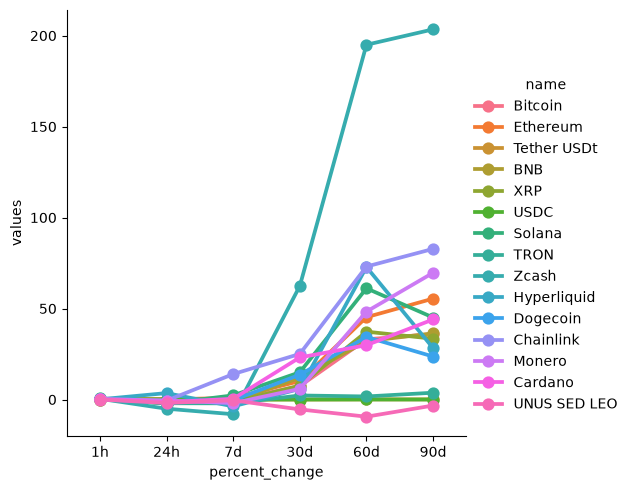

In [33]:
sns.catplot(x='percent_change',y='values',hue='name',data=df7,kind='point')

In [38]:
df8 = final_df[['name','quote.USD.price','timestamp']]
df8 = df8.query("name == 'Bitcoin'")
df8


,name,quote.USD.price,timestamp
0,Bitcoin,83767.65949,2026-10-01 19:45:38.984447
15,Bitcoin,83764.00252,2026-10-01 19:46:40.558423
30,Bitcoin,83810.98065,2026-10-01 19:47:41.791241
45,Bitcoin,83867.82288,2026-10-01 19:48:43.433426
60,Bitcoin,83953.05656,2026-10-01 19:49:44.874990


<Axes: xlabel='quote.USD.price', ylabel='timestamp'>

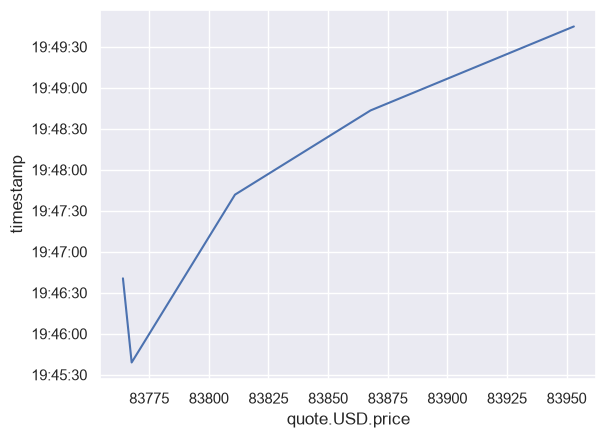

In [42]:
sns.set_theme(style="darkgrid")
sns.lineplot(x='quote.USD.price',y='timestamp',data = df8)